# 02. Улучшение нейросетевой модели для выявления банковских рисков

**Цель:** сравнить несколько подходов к fine-tuning `microsoft/mdeberta-v3-base` для бинарной классификации новостей. Основная метрика — **F1-score положительного класса (`alert_flag=1`)**. Дополнительно оцениваем Precision, Recall и Average Precision.

Используем **один неизменный датасет** и готовые `train` / `valid` / `test`. Архитектура и порог выбираются **только на validation**. Тестовая выборка предназначена для заключительной оценки, а не для перебора настроек.

Данные содержат очень мало положительных примеров: в validation — 40, в test — 38. Поэтому разница даже в 1–2 классификациях заметно меняет F1. Значение F1 выше 0,90 — **желаемый, но не гарантированный** результат.

> Важное ограничение: исходный test уже использовался в предыдущих экспериментах. Его повторная проверка не является новым независимым подтверждением улучшения.

## 1. Среда обучения

Эксперименты выполнялись в Kaggle с GPU. Для первоначальной загрузки модели необходим доступ к Internet; исходный CSV подключается как входной набор данных.

In [14]:
import os, sys, importlib.util, subprocess
os.environ['USE_TF'] = '0'
os.environ['USE_FLAX'] = '0'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
missing = [name for name in ['transformers','accelerate','sentencepiece','safetensors']
           if importlib.util.find_spec(name) is None]
if missing:
    print('Устанавливаю отсутствующие пакеты:', missing)
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
    print('После установки пакетов может потребоваться перезапуск ядра.')
else:
    print('Основные библиотеки доступны. Ничего переустанавливать не нужно.')

Основные библиотеки доступны. Ничего переустанавливать не нужно.


## 2. Настройки эксперимента

Режим `PLAN="screen"` охватывает четыре представления текста. В режиме `PLAN="all"` предусмотрены дополнительные функции потерь, learning rate и seed; полный план включает до девяти обучений. Бюджет времени и числа запусков ограничен в коде. Флаг `RUN_FINAL_TEST` отделяет итоговую оценку от подбора конфигураций.

In [15]:
from pathlib import Path
import os, re, json, time, gc, math, hashlib, inspect, shutil, warnings, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from IPython.display import display
from sklearn.metrics import (f1_score, precision_score, recall_score,
    average_precision_score, precision_recall_curve, confusion_matrix,
    ConfusionMatrixDisplay)
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
    DataCollatorWithPadding, Trainer, TrainingArguments, EarlyStoppingCallback, set_seed)
import transformers, accelerate

assert torch.cuda.is_available(), 'Для обучения требуется GPU.'
print('GPU:', torch.cuda.get_device_name(0))
print('PyTorch:', torch.__version__, '| Transformers:', transformers.__version__,
      '| Accelerate:', accelerate.__version__)

MODEL_ID = 'microsoft/mdeberta-v3-base'
MODEL_REVISION = 'a0484667b22365f84929a935b5e50a51f71f159d'
PLAN = 'all'                    # 'screen' или 'all'
MAX_RUNS = 9                       # только для полного плана
MAX_TOTAL_MINUTES = 150           # ограничение времени ОБУЧЕНИЯ за один запуск
SEED = 42
BATCH_SIZE = 4
GRAD_ACCUM = 4
OUTPUT = Path('/kaggle/working/bank_risk_dl_experiments')
OUTPUT.mkdir(parents=True, exist_ok=True)

# Оценка test выключена в ходе подбора конфигураций.
# В финальной ячейке есть отдельный RUN_FINAL_TEST.
set_seed(SEED)

GPU: Tesla T4
PyTorch: 2.11.0+cu128 | Transformers: 5.16.1 | Accelerate: 1.14.0


## 3. Загрузка и проверка данных

Используем исходные метки и разбиение без изменений. Поля `found_risk_keywords` и `risk_type_4cls` не поступают на вход модели. Перед обучением проверяем, что группы событий не пересекаются между выборками.

In [16]:
all_files = sorted(Path('/kaggle/input').rglob('bank_risk_dataset.csv'))
if not all_files:
    all_files = sorted(Path('/kaggle/working').rglob('bank_risk_dataset.csv'))
assert all_files, 'Среди входных файлов отсутствует bank_risk_dataset.csv.'
assert len(all_files) == 1, f'Найдено несколько датасетов: {all_files}. Укажите один конкретный путь.'
DATA_PATH = all_files[0]
DATA_SHA = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
df = pd.read_csv(DATA_PATH)
required = {'sample_id','event_group_id','split','title','entity_norm','text_fragment','alert_flag'}
assert required.issubset(df.columns), f'Нет столбцов: {required-set(df.columns)}'
assert len(df)==5041, f'Ожидалось 5041 наблюдение; сейчас {len(df)}'
assert set(df['split']) == {'train','valid','test'}
assert df['alert_flag'].isin([0,1]).all()
assert df['sample_id'].is_unique
parts = {s: df.loc[df['split']==s].copy().reset_index(drop=True) for s in ('train','valid','test')}
assert [len(parts[k]) for k in ('train','valid','test')] == [3535,755,751]
for s in parts:
    parts[s]['text_fragment'] = parts[s]['text_fragment'].fillna('').astype(str)
    parts[s]['title'] = parts[s]['title'].fillna('').astype(str)
    parts[s]['entity_norm'] = parts[s]['entity_norm'].fillna('Неизвестный банк').astype(str)
    assert parts[s]['text_fragment'].str.strip().ne('').all(), f'Пустые тексты в {s}'
for a,b in [('train','valid'),('train','test'),('valid','test')]:
    shared = set(parts[a]['event_group_id']) & set(parts[b]['event_group_id'])
    assert not shared, f'Найдены общие event_group_id для {a} и {b}: {len(shared)}'
print('Источник:', DATA_PATH)
print('SHA256:', DATA_SHA)
print('Разбиение:')
display(df.groupby('split')['alert_flag'].agg(['count','sum']).rename(columns={'sum':'Риск'}))

Источник: /kaggle/input/datasets/victordoynikov/bank-risks/bank_risk_dataset.csv
SHA256: 52333a13e7fb6f6c4162486198fbf1d1ab368672a8974295995580a1924f67f3
Разбиение:


,count,Риск
split,,
test,751,38
train,3535,176
valid,755,40


## 4. Представление текста и токенизация

Сравниваем четыре варианта: только текст; пара «банк, текст»; пара «банк, заголовок + текст»; пара «банк, заголовок + предложения с упоминанием банка». Если упоминания банка не найдены, последний вариант использует исходный текст. Риск извлекается **не по словарю рискованных слов**, а по контексту банка.

In [17]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=MODEL_REVISION, use_fast=False)
collator = DataCollatorWithPadding(tokenizer=tokenizer, pad_to_multiple_of=8)

def with_title(title, text):
    # Заголовок часто уже входит в text_fragment — избегаем дублирования.
    title, text = title.strip(), text.strip()
    if not title or title.lower() in text[:max(300, len(title)+40)].lower():
        return text
    return title + '. ' + text

def bank_context(bank, text, title):
    sentences = re.split(r'(?<=[.!?])\s+', text.strip())
    words = [w for w in re.findall(r'\w+', bank.casefold()) if len(w) >= 4]
    hit = [i for i, s in enumerate(sentences) if bank.casefold() in s.casefold()
           or any(w in s.casefold() for w in words)]
    if not hit:
        return with_title(title, text)
    selected = set()
    for i in hit:
        selected.update(range(max(0,i-1), min(len(sentences),i+2)))
    excerpt = ' '.join(sentences[i] for i in sorted(selected))
    return with_title(title, excerpt)

class NewsDataset(torch.utils.data.Dataset):
    def __init__(self, frame, mode='text', max_length=256):
        texts = frame['text_fragment'].tolist()
        titles = frame['title'].tolist()
        banks = frame['entity_norm'].tolist()
        if mode == 'text':
            self.encodings = tokenizer(texts, truncation=True, max_length=max_length)
        elif mode == 'bank_pair':
            self.encodings = tokenizer(banks, text_pair=texts,
                                       truncation='only_second', max_length=max_length)
        elif mode == 'bank_title':
            snippets = [with_title(t,x) for t,x in zip(titles,texts)]
            self.encodings = tokenizer(banks, text_pair=snippets,
                                       truncation='only_second', max_length=max_length)
        elif mode == 'bank_context':
            snippets = [bank_context(b,x,t) for b,x,t in zip(banks,texts,titles)]
            self.encodings = tokenizer(banks, text_pair=snippets,
                                       truncation='only_second', max_length=max_length)
        else:
            raise ValueError(mode)
        self.labels = frame['alert_flag'].astype(int).tolist()
    def __len__(self): return len(self.labels)
    def __getitem__(self, i):
        return {**{key: values[i] for key,values in self.encodings.items()},
                'labels': self.labels[i]}

_dataset_cache = {}
def get_dataset(split, mode, length=256):
    key = (split,mode,length)
    if key not in _dataset_cache:
        _dataset_cache[key] = NewsDataset(parts[split],mode,length)
    return _dataset_cache[key]

print('Длина примера (text):', len(get_dataset('train','text')[0]['input_ids']))

Длина примера (text): 119


## 5. Метрики и оптимальный порог

F1 рассчитывается для `alert_flag = 1`. Порог выбираем на **валидационной** Precision–Recall-кривой, а не на test. На каждой эпохе порог может меняться, и лучшие веса выбираются по validation F1 с таким порогом. Это даёт оптимистичную оценку на небольшом validation; поэтому отдельно сохраняем Precision, Recall и AP.

In [18]:
def pos_scores(logits):
    if isinstance(logits, tuple): logits = logits[0]
    a = np.asarray(logits, dtype=np.float64)
    a = a - a.max(axis=-1,keepdims=True)
    z = np.exp(a)
    return (z/z.sum(axis=-1,keepdims=True))[:,1]

def best_threshold(y, scores):
    prec, rec, thresholds = precision_recall_curve(y, scores)
    f1_vals = 2*prec[:-1]*rec[:-1]/np.maximum(prec[:-1]+rec[:-1],1e-12)
    best = np.where(np.isclose(f1_vals,f1_vals.max(),rtol=0,atol=1e-12))[0][-1]
    return float(thresholds[best])

def score_metrics(y, scores, threshold=None):
    y = np.asarray(y, dtype=int)
    scores = np.asarray(scores, dtype=float)
    if threshold is None: threshold = best_threshold(y, scores)
    pred = (scores >= threshold).astype(int)
    tn,fp,fn,tp = confusion_matrix(y,pred,labels=[0,1]).ravel()
    return {'f1':float(f1_score(y,pred,zero_division=0)),
        'precision':float(precision_score(y,pred,zero_division=0)),
        'recall':float(recall_score(y,pred,zero_division=0)),
        'ap':float(average_precision_score(y,scores)),
        'threshold':float(threshold),'tp':int(tp),'fp':int(fp),'fn':int(fn),'tn':int(tn)}

def epoch_metrics(pred):
    logits = pred.predictions
    if isinstance(logits, tuple): logits=logits[0]
    return score_metrics(pred.label_ids, pos_scores(logits))

# Независимая мини-проверка формулы и порога (без обучения).
_y=np.array([0,0,1,1]);_s=np.array([.1,.3,.7,.9]);_m=score_metrics(_y,_s)
assert _m['f1']==1 and _m['tp']==2 and _m['fp']==0
print('Проверка F1 и порога пройдена.')

Проверка F1 и порога пройдена.


## 6. Настройка обучения и функций потерь

Первый этап использует обычную Cross Entropy. Во втором этапе проверяем **взвешенную CE**, **Focal Loss** и меньший learning rate. Вес положительного класса берём по *корню* из отношения частот train — это менее агрессивная коррекция, чем полное обратное соотношение.

Параметры модели остаются FP32; смешанная точность FP16 применяется в `Trainer`. Это важно для устранения ошибки `Attempting to unscale FP16 gradients`.

In [19]:
train_y = parts['train']['alert_flag'].to_numpy()
positive_weight = float(np.sqrt((train_y==0).sum() / (train_y==1).sum()))
print('Вес положительного класса для отдельного эксперимента:',round(positive_weight,3))

class WeightedTrainer(Trainer):
    # Совместимо с поддержкой num_items_in_batch при gradient accumulation.
    loss_is_scaled_for_ga = True
    def __init__(self, *args, loss_mode='weighted', positive_weight=1., **kwargs):
        self.loss_mode=loss_mode
        self.positive_weight=float(positive_weight)
        super().__init__(*args,**kwargs)
    def compute_loss(self, model, inputs, return_outputs=False,
                     num_items_in_batch=None, **kwargs):
        labels = inputs['labels']
        features = {k:v for k,v in inputs.items() if k != 'labels'}
        outputs = model(**features)
        logits = outputs.logits.float()
        weights = torch.tensor([1.,self.positive_weight],device=logits.device,dtype=torch.float32)
        logp=F.log_softmax(logits,dim=-1)
        log_pt=logp.gather(1,labels.long().view(-1,1)).squeeze(1)
        pt=log_pt.exp()
        cls_weight=weights[labels.long()]
        if self.loss_mode=='weighted':
            loss_each = -cls_weight*log_pt
        elif self.loss_mode=='focal':
            loss_each = -cls_weight*(1-pt)**2*log_pt
        else:
            raise ValueError(self.loss_mode)
        denom = (num_items_in_batch if num_items_in_batch is not None else labels.numel())
        if torch.is_tensor(denom): denom=denom.to(logits.device).clamp_min(1)
        else: denom=max(1,int(denom))
        loss = loss_each.sum()/denom
        return (loss,outputs) if return_outputs else loss

# Автоматически учитываем различия API Transformers 4.x и 5.x,
# не подменяя и не устанавливая старые зависимости.
args_fields = set(inspect.signature(TrainingArguments).parameters)
trainer_fields = set(inspect.signature(Trainer).parameters)

def train_args(output_dir, cfg):
    kwargs=dict(output_dir=str(output_dir),num_train_epochs=cfg['epochs'],
        learning_rate=cfg['learning_rate'],per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=4,gradient_accumulation_steps=GRAD_ACCUM,
        weight_decay=0.01, lr_scheduler_type='linear',optim='adamw_torch',
        max_grad_norm=1.,fp16=not torch.cuda.is_bf16_supported(),
        bf16=torch.cuda.is_bf16_supported(), save_strategy='epoch',
        logging_strategy='epoch',load_best_model_at_end=True,
        metric_for_best_model='f1',greater_is_better=True,
        save_total_limit=1,seed=cfg['seed'],data_seed=cfg['seed'],
        report_to='none',dataloader_num_workers=0)
    if 'eval_strategy' in args_fields:kwargs['eval_strategy']='epoch'
    elif 'evaluation_strategy' in args_fields:kwargs['evaluation_strategy']='epoch'
    else:raise RuntimeError('Версия transformers не поддерживает оценку по эпохам.')
    if 'warmup_ratio' in args_fields: kwargs['warmup_ratio']=0.1
    elif 'warmup_steps' in args_fields: kwargs['warmup_steps']=0.1
    if 'save_only_model' in args_fields:kwargs['save_only_model']=True
    if 'save_safetensors' in args_fields:kwargs['save_safetensors']=True
    clean={k:v for k,v in kwargs.items() if k in args_fields}
    return TrainingArguments(**clean)

Вес положительного класса для отдельного эксперимента: 4.369


## 7. Серия экспериментов

План **screen**: сравниваем четыре представления текста, один seed и обычную CE. План **all** после этого добавит weighted CE, Focal Loss, дополнительный learning rate и проверку seed. Выбор дальнейших вариантов происходит на validation, а не на test.

После каждого эксперимента сохраняются `metrics.json`, `history.csv`, предсказания validation и лучшая модель. Если этот же эксперимент уже полностью сохранён в текущем `/kaggle/working`, он не запускается заново. Для сохранения артефактов между сессиями используется Output версии Kaggle.

In [20]:
BASE = dict(seed=42,max_length=256,learning_rate=2e-5,epochs=6,
            loss_mode='standard')
SCREEN = [dict(BASE,mode=m,name=f'screen_{m}')
          for m in ('text','bank_pair','bank_title','bank_context')]

def save_json(path, obj):
    path=Path(path)
    path.write_text(json.dumps(obj,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')

def make_trainer(model, args, cfg, train_ds, valid_ds):
    common = dict(model=model,args=args,train_dataset=train_ds,eval_dataset=valid_ds,
                  data_collator=collator,compute_metrics=epoch_metrics,
                  callbacks=[EarlyStoppingCallback(early_stopping_patience=2)])
    if 'processing_class' in trainer_fields:common['processing_class']=tokenizer
    elif 'tokenizer' in trainer_fields:common['tokenizer']=tokenizer
    if cfg['loss_mode']=='standard': return Trainer(**common)
    return WeightedTrainer(**common,loss_mode=cfg['loss_mode'],
                           positive_weight=positive_weight)

start_time = time.monotonic()
run_count = 0

def run_experiment(cfg):
    global run_count
    run=OUTPUT / 'runs' / cfg['name']
    run.mkdir(parents=True,exist_ok=True)
    metrics_file=run/'metrics.json'
    config_file=run/'run_config.json'
    signature={'config':cfg,'dataset_sha256':DATA_SHA,
               'model_id':MODEL_ID,'model_revision':MODEL_REVISION,
               'transformers_version':transformers.__version__}
    if config_file.exists():
        assert json.loads(config_file.read_text()) == signature, ('Параметры уже существующего '
            'эксперимента изменились. Создайте новое имя для этой конфигурации.')
    else:save_json(config_file,signature)
    if metrics_file.exists() and (run/'best_model'/'config.json').exists():
        print('Готовый эксперимент:',cfg['name'])
        return json.loads(metrics_file.read_text())
    elapsed=(time.monotonic()-start_time)/60
    if run_count>=MAX_RUNS or elapsed>=MAX_TOTAL_MINUTES:
        print('Достигнут бюджет вычислений. Не запущен:', cfg['name'])
        return None
    run_count+=1
    print(f'\nЭксперимент {run_count}: {cfg["name"]} | время {elapsed:.1f} мин')
    set_seed(cfg['seed'])
    model=AutoModelForSequenceClassification.from_pretrained(
        MODEL_ID,revision=MODEL_REVISION,num_labels=2,
        id2label={0:'NO_RISK',1:'RISK'},label2id={'NO_RISK':0,'RISK':1})
    model=model.float()  # параметры FP32, AMP включает сам Trainer
    assert all(p.dtype==torch.float32 for p in model.parameters() if p.requires_grad)
    train_ds=get_dataset('train',cfg['mode'],cfg['max_length'])
    valid_ds=get_dataset('valid',cfg['mode'],cfg['max_length'])
    args=train_args(run/'checkpoints',cfg)
    trainer=make_trainer(model,args,cfg,train_ds,valid_ds)
    trainer.train()
    trainer.save_model(str(run/'best_model'))
    tokenizer.save_pretrained(str(run/'best_model'))
    validation=trainer.predict(valid_ds,metric_key_prefix='valid')
    logits=validation.predictions[0] if isinstance(validation.predictions,tuple) else validation.predictions
    scores=pos_scores(logits)
    metrics=score_metrics(validation.label_ids,scores)
    rec={'name':cfg['name'],'mode':cfg['mode'],'seed':cfg['seed'],
         'loss_mode':cfg['loss_mode'],'learning_rate':cfg['learning_rate'],
         'max_length':cfg['max_length'],'epochs':cfg['epochs'],**metrics}
    save_json(metrics_file,rec)
    preds=parts['valid'][['sample_id','alert_flag']].copy()
    preds['score']=scores
    preds['prediction']=(scores>=metrics['threshold']).astype(int)
    preds.to_csv(run/'valid_predictions.csv',index=False)
    pd.DataFrame(trainer.state.log_history).to_csv(run/'history.csv',index=False)
    # Оптимизатор для простого применения модели не нужен. Оставляем лучшие веса.
    cp=run/'checkpoints'
    if cp.exists():shutil.rmtree(cp)
    print('Validation F1=',round(metrics['f1'],4),'AP=',round(metrics['ap'],4),
          'Recall=',round(metrics['recall'],4))
    del validation,trainer,model,train_ds,valid_ds
    gc.collect();torch.cuda.empty_cache()
    return rec

records=[]
for cfg in SCREEN:
    result=run_experiment(cfg)
    if result is None:break
    records.append(result)
if not records:raise RuntimeError('Ни один эксперимент не завершён.')

Готовый эксперимент: screen_text
Готовый эксперимент: screen_bank_pair
Готовый эксперимент: screen_bank_title
Готовый эксперимент: screen_bank_context


## 8. Расширенные эксперименты (при `PLAN = "all"`)

На втором этапе используем лучший способ представления входа по validation F1. Тестируем взвешенную CE, Focal Loss и learning rate 1e-5. После этого у лучшей конфигурации проверяем seed 123 и 2026, сохраняя все метрики, а не выбирая красивую случайную инициализацию без отчёта об устойчивости.

In [21]:
if PLAN not in ('screen','all'):
    raise ValueError('PLAN должен быть screen или all')
if PLAN=='all' and len(records)==len(SCREEN):
    best_screen=max(records,key=lambda x:(x['f1'],x['ap']))
    mode=best_screen['mode']
    tuned=[dict(BASE,mode=mode,loss_mode='weighted',name=f'tune_{mode}_weighted'),
           dict(BASE,mode=mode,loss_mode='focal',name=f'tune_{mode}_focal'),
           dict(BASE,mode=mode,learning_rate=1e-5,name=f'tune_{mode}_lr1e5')]
    for cfg in tuned:
        r=run_experiment(cfg)
        if r is None:break
        records.append(r)
    if len(records)==len(SCREEN)+len(tuned):
        leader=max(records,key=lambda x:(x['f1'],x['ap']))
        selected_conf = next(c for c in SCREEN+tuned if c['name']==leader['name'])
        for seed in (123,2026):
            cfg={**selected_conf,'seed':seed,'name':f"repeat_{leader['mode']}_{leader['loss_mode']}_{seed}"}
            r=run_experiment(cfg)
            if r is None:break
            records.append(r)

summary=pd.DataFrame(records).sort_values(['f1','ap'],ascending=False)
summary.to_csv(OUTPUT/'validation_comparison.csv',index=False)
cols=['name','mode','seed','loss_mode','f1','precision','recall','ap','tp','fp','fn','threshold']
display(summary[cols].round(4))
win=summary.iloc[0].to_dict()
save_json(OUTPUT/'selection.json',{'selected_run':win['name'],
     'criterion':'maximum validation F1; tie-breaker AP','validation':win,
     'dataset_sha256':DATA_SHA})
print('Лучший по validation F1:',win['name'],'F1=',round(win['f1'],4))
if PLAN=='all':
    repetitions=summary.loc[summary['name'].str.startswith('repeat_')]
    if not repetitions.empty:
        display(repetitions[['name','seed','f1','ap']].round(4))
        # Сопоставляем две дополнительные инициализации с исходной 42.
        seed42 = summary.loc[summary['name'] == leader['name'], ['name','seed','f1','ap']]
        seed_report = pd.concat([seed42, repetitions[['name','seed','f1','ap']]], ignore_index=True)
        display(seed_report.round(4))
        print('F1 по seed: среднее =', round(seed_report['f1'].mean(),4),
              ', стандартное отклонение =', round(seed_report['f1'].std(ddof=1),4))
        seed_report.to_csv(OUTPUT/'seed_stability.csv', index=False)
        print('Это оценка разброса на одной validation, не оценка генерализации.')


Эксперимент 1: tune_bank_context_weighted | время 0.0 мин


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/mdeberta-v3-base
Key                                        | Status     | 
-------------------------------------------+------------+-
mask_predictions.dense.weight              | UNEXPECTED | 
mask_predictions.LayerNorm.weight          | UNEXPECTED | 
deberta.embeddings.word_embeddings._weight | UNEXPECTED | 
lm_predictions.lm_head.dense.weight        | UNEXPECTED | 
mask_predictions.LayerNorm.bias            | UNEXPECTED | 
mask_predictions.classifier.bias           | UNEXPECTED | 
lm_predictions.lm_head.dense.bias          | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias      | UNEXPECTED | 
mask_predictions.dense.bias                | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight    | UNEXPECTED | 
mask_predictions.classifier.weight         | UNEXPECTED | 
lm_predictions.lm_head.bias                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
pooler.dense.weight 

Epoch,Training Loss,Validation Loss,F1,Precision,Recall,Ap,Threshold,Tp,Fp,Fn,Tn
1,0.570252,0.447601,0.666667,0.658537,0.675000,0.635934,0.399189,27,14,13,701
2,0.285536,0.605309,0.692308,0.562500,0.900000,0.667755,0.005834,36,28,4,687
3,0.206260,0.440276,0.694737,0.600000,0.825000,0.727692,0.022298,33,22,7,693
4,0.144638,0.394813,0.714286,0.681818,0.750000,0.769365,0.618921,30,14,10,701
5,0.081695,0.477763,0.716049,0.707317,0.725000,0.781441,0.514318,29,12,11,703
6,0.052001,0.437837,0.712644,0.659574,0.775000,0.764465,0.243788,31,16,9,699


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (67 outputs left out)

Лучший по validation F1: screen_bank_context F1= 0.7949


,name,seed,f1,ap
8,repeat_bank_context_standard_2026,2026,0.7470,0.7506
7,repeat_bank_context_standard_123,123,0.6977,0.7092


,name,seed,f1,ap
0,screen_bank_context,42,0.7949,0.7466
1,repeat_bank_context_standard_2026,2026,0.7470,0.7506
2,repeat_bank_context_standard_123,123,0.6977,0.7092


F1 по seed: среднее = 0.7465 , стандартное отклонение = 0.0486
Это оценка разброса на одной validation, не оценка генерализации.


## 9. Графики, ошибки и выбор модели

Диаграмма отражает только validation: в этом разделе **нет тестовых метрик**. Сохраняем список False Positive и False Negative на validation, чтобы понять слабые стороны модели, не используя test для улучшения.

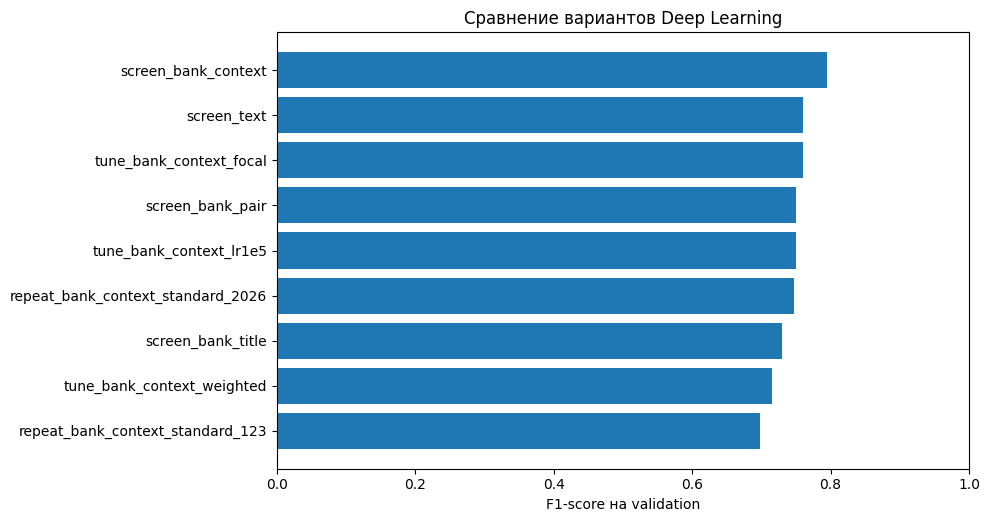

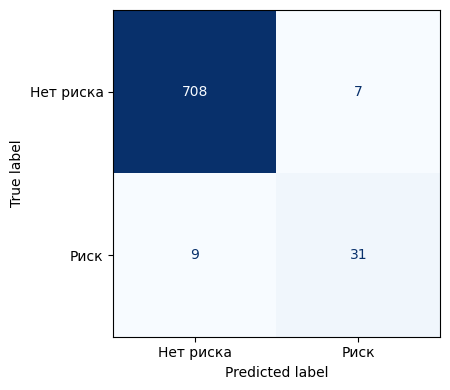

Ошибок на validation: 16 | пропусков: 9


In [22]:
fig,ax=plt.subplots(figsize=(10,max(4,0.48*len(summary)+1)))
plot=summary.sort_values('f1')
ax.barh(plot['name'],plot['f1'])
ax.set_xlabel('F1-score на validation');ax.set_xlim(0,1)
ax.set_title('Сравнение вариантов Deep Learning')
fig.tight_layout();fig.savefig(OUTPUT/'validation_f1.png',dpi=150)
plt.show()

selected_dir=OUTPUT/'runs'/win['name']
vp=pd.read_csv(selected_dir/'valid_predictions.csv')
fig,ax=plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay.from_predictions(vp['alert_flag'],vp['prediction'],
   labels=[0,1],display_labels=['Нет риска','Риск'],ax=ax,cmap='Blues',colorbar=False)
fig.tight_layout();fig.savefig(OUTPUT/'validation_confusion_matrix.png',dpi=150)
plt.show()
errors=vp.loc[vp['alert_flag']!=vp['prediction']].copy()
errors['error_type']=np.where(errors['alert_flag']==1,'FN','FP')
errors.to_csv(OUTPUT/'validation_errors.csv',index=False)
print('Ошибок на validation:',len(errors),'| пропусков:',(errors['error_type']=='FN').sum())

baseline_path = next(iter(sorted(Path('/kaggle/input').rglob('baseline_metrics.csv'))), None)
if baseline_path is not None:
    baseline_table = pd.read_csv(baseline_path)
    col = 'split' if 'split' in baseline_table.columns else None
    if col:
        classic = baseline_table.loc[baseline_table[col].isin(['valid','validation'])]
        print('Сравнение с классическим baseline — только validation F1:')
        display(classic[['model','f1','precision','recall','ap']].round(4))


## 10. Итоговая оценка на test

Оценка относится к модели, зафиксированной в `selection.json` по validation F1. В коде она отделена флагом `RUN_FINAL_TEST` и проверкой сохранённых результатов. Тестовые показатели не служат критерием перебора новых конфигураций. Историческое использование этого test ограничивает независимость итоговой оценки.

In [23]:
RUN_FINAL_TEST = False  # Включить только ПОСЛЕ фиксации победителя по validation.

if RUN_FINAL_TEST:
    selected=json.loads((OUTPUT/'selection.json').read_text())
    winner=selected['validation']
    test_path=OUTPUT/'test_metrics.json'
    if test_path.exists():
        print('Тест уже был рассчитан для данной серии. Повторная оценка не выполняется.')
        display(pd.DataFrame([json.loads(test_path.read_text())['metrics']]))
    else:
        run=OUTPUT/'runs'/winner['name']
        cfg=json.loads((run/'run_config.json').read_text())['config']
        set_seed(cfg['seed'])
        best_model=AutoModelForSequenceClassification.from_pretrained(run/'best_model').float()
        eval_config={'output_dir':str(OUTPUT/'eval_temp'),'per_device_eval_batch_size':4,
                     'fp16':not torch.cuda.is_bf16_supported(),
                     'bf16':torch.cuda.is_bf16_supported(), 'report_to':'none'}
        eval_args=TrainingArguments(**{k:v for k,v in eval_config.items() if k in args_fields})
        common={'model':best_model,'args':eval_args,'data_collator':collator}
        if 'processing_class' in trainer_fields:common['processing_class']=tokenizer
        elif 'tokenizer' in trainer_fields:common['tokenizer']=tokenizer
        evaluator=Trainer(**common)
        test_out=evaluator.predict(get_dataset('test',cfg['mode'],cfg['max_length']))
        logits=test_out.predictions[0] if isinstance(test_out.predictions,tuple) else test_out.predictions
        scores=pos_scores(logits)
        m=score_metrics(test_out.label_ids,scores,threshold=winner['threshold'])
        preds=parts['test'][['sample_id','alert_flag']].copy()
        preds['score']=scores;preds['prediction']=(scores>=winner['threshold']).astype(int)
        preds.to_csv(OUTPUT/'test_predictions.csv',index=False)
        save_json(test_path,{'selection':winner['name'], 'threshold':winner['threshold'],
             'dataset_sha256':DATA_SHA,'metrics':m})
        print('FINAL TEST:',m)
        if m['f1']>=0.9:
            print('Целевой порог F1 >= 0.90 достигнут на данном тестовом разбиении.')
        else:
            print('F1 ниже 0.90. Дополнительный подбор по этому test не выполняем.')
        del evaluator,best_model,test_out
        torch.cuda.empty_cache()
else:
    print('Test не запускался. Выбор конфигураций сделан исключительно по validation.')
print('Все результаты сохраняются в',OUTPUT)

Test не запускался. Выбор конфигураций сделан исключительно по validation.
Все результаты сохраняются в /kaggle/working/bank_risk_dl_experiments


## 11. Результаты и ограничения

Таблица `validation_comparison.csv` содержит результаты сравнения конфигураций, а `selection.json` — выбранную по validation F1 модель. В каталоге запуска сохранялись веса, токенизатор, история эпох и предсказания. Локальный отчёт 03 использует сохранённые числовые результаты; веса mDeBERTa хранятся отдельно в Kaggle.

В validation лишь 40 положительных примеров. Ранее наблюдавшийся test, дисбаланс классов и возможные смысловые повторы ограничивают переносимость оценки. Более высокий F1 на этой выборке сам по себе не подтверждает качество на новом потоке новостей.